# 02 · Experimentos e resultados

Este notebook só **lê** os registros gerados pelos scripts em `scripts/` (cada treino salva um JSON em
`outputs/runs/`, e o estudo Optuna fica em `outputs/optuna.db`) e produz as tabelas e figuras do relatório.

| Script | Experimento |
|---|---|
| `02_capacidade.py` | profundidade × largura, em duas escalas de treino (20 mil e 500 mil exemplos) |
| `03_regularizacao.py` | dropout, L1, L2, BatchNorm, LayerNorm e early stopping numa MLP 4×512 |
| `04_optuna.py` | busca de hiperparâmetros (TPE + poda por mediana), 60 trials |
| `05_modelos_finais.py` | 3 arquiteturas selecionadas + referências, treino completo, 3 sementes, testes 2022 e 2023 |

In [1]:
import sys, json
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from enem import config as C, plots
from enem.plots import SERIES, INK_2, MUTED
plots.setup()
pd.set_option("display.max_columns", 50, "display.width", 160, "display.float_format", "{:,.2f}".format)

In [2]:
from enem.runs import load_results, summary_table
from enem.pipeline import load_meta
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
ESCALAS = {"n20k": "20 mil exemplos de treino", "n500k": "500 mil exemplos de treino"}
def curvas(ax, r, titulo=None, ymax=None):
    h = pd.DataFrame(r["history"])
    ax.plot(h["epoch"], h["train_rmse"], color=SERIES[0], label="treino")
    ax.plot(h["epoch"], h["val_rmse"], color=SERIES[1], label="validação")
    b = h.loc[h["val_rmse"].idxmin()]
    ax.scatter([b["epoch"]], [b["val_rmse"]], s=36, color=SERIES[1], edgecolor=plots.SURFACE, linewidth=1.5, zorder=3)
    if titulo: ax.set_title(titulo, fontsize=9)
    if ymax: ax.set_ylim(0, ymax)

## 1. Capacidade: profundidade × largura

Sem regularização, LR constante e todas as épocas (120 na escala de 20 mil, 30 na de 500 mil). `melhor` = melhor época na validação (o que o early stopping pegaria); `final` = última época. Validação: 100 mil exemplos de 2022.

In [3]:
cap = load_results("capacidade")
tcap = summary_table(cap, ["escala", "profundidade", "largura"]).sort_values(["escala", "profundidade", "largura"])
tcap.to_csv(C.TAB_DIR / "capacidade.csv", index=False)
tcap

,escala,profundidade,largura,n_params,melhor_epoca,val_rmse_melhor,treino_rmse_melhor,val_r2_melhor,val_rmse_final,treino_rmse_final,gap_final,tempo_treino_s,tempo_epoca_s
0,n20k,0,0,28082,13,71.18,69.84,0.34,73.22,66.85,6.37,7.60,0.06
2,n20k,1,32,34625,6,70.56,68.59,0.35,86.20,46.13,40.07,10.63,0.09
1,n20k,1,128,54881,6,70.56,66.61,0.35,99.57,21.03,78.54,11.83,0.10
3,n20k,1,512,135905,3,70.71,67.48,0.35,92.99,8.80,84.19,12.91,0.11
5,n20k,2,32,35681,6,70.62,68.01,0.35,90.10,40.65,49.45,13.67,0.11
4,n20k,2,128,71393,3,70.74,68.18,0.35,99.56,8.59,90.98,15.14,0.13
6,n20k,2,512,398561,3,70.88,66.19,0.35,81.33,8.46,72.88,21.07,0.18
8,n20k,3,32,36737,6,70.70,68.05,0.35,91.09,38.40,52.69,16.06,0.13
7,n20k,3,128,87905,3,70.74,68.18,0.35,94.15,8.79,85.36,18.22,0.15
9,n20k,3,512,661217,2,70.95,67.84,0.35,78.92,6.46,72.46,28.90,0.24


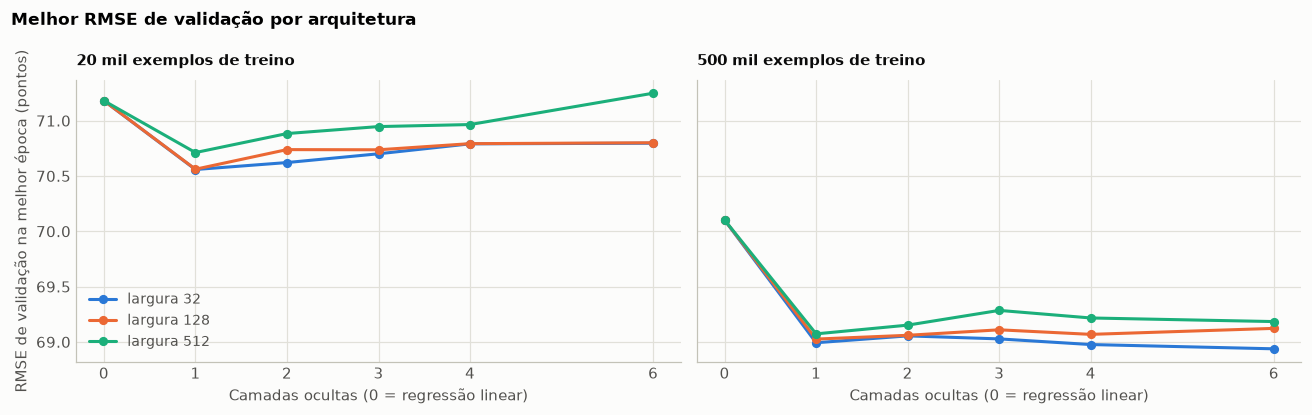

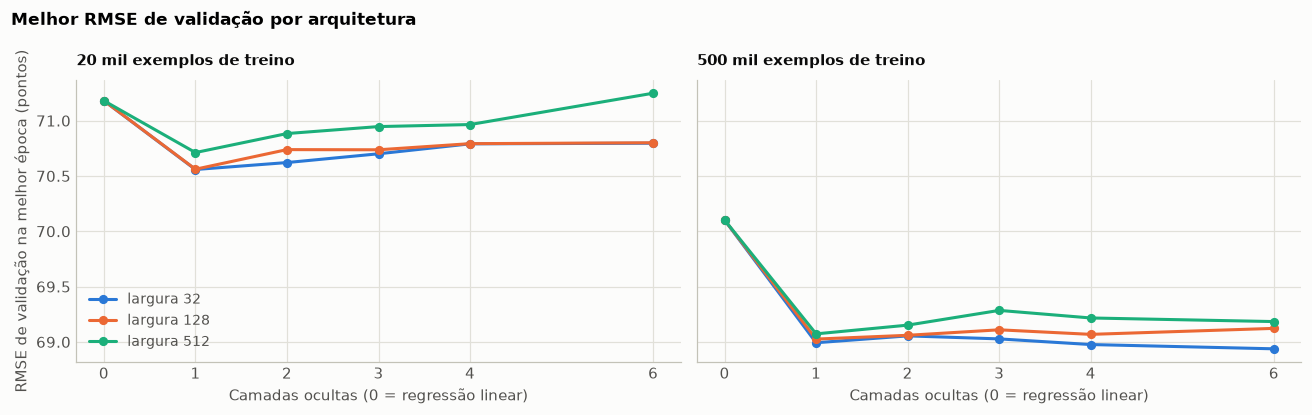

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (esc, titulo) in zip(axes, ESCALAS.items()):
    t = tcap[tcap["escala"] == esc]
    lin = t[t["profundidade"] == 0]["val_rmse_melhor"].iloc[0]
    for i, w in enumerate([32, 128, 512]):
        tw = t[t["largura"] == w].sort_values("profundidade")
        x = [0] + tw["profundidade"].tolist(); y = [lin] + tw["val_rmse_melhor"].tolist()
        ax.plot(x, y, marker="o", color=SERIES[i], label=f"largura {w}")
        yf = [t[t["profundidade"] == 0]["val_rmse_final"].iloc[0]] + tw["val_rmse_final"].tolist()
    ax.set_title(titulo, fontsize=10); ax.set_xlabel("Camadas ocultas (0 = regressão linear)")
    ax.set_xticks([0, 1, 2, 3, 4, 6])
axes[0].set_ylabel("RMSE de validação na melhor época (pontos)"); axes[0].legend()
fig.suptitle("Melhor RMSE de validação por arquitetura", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout(); plots.save(fig, "cap_melhor_val")

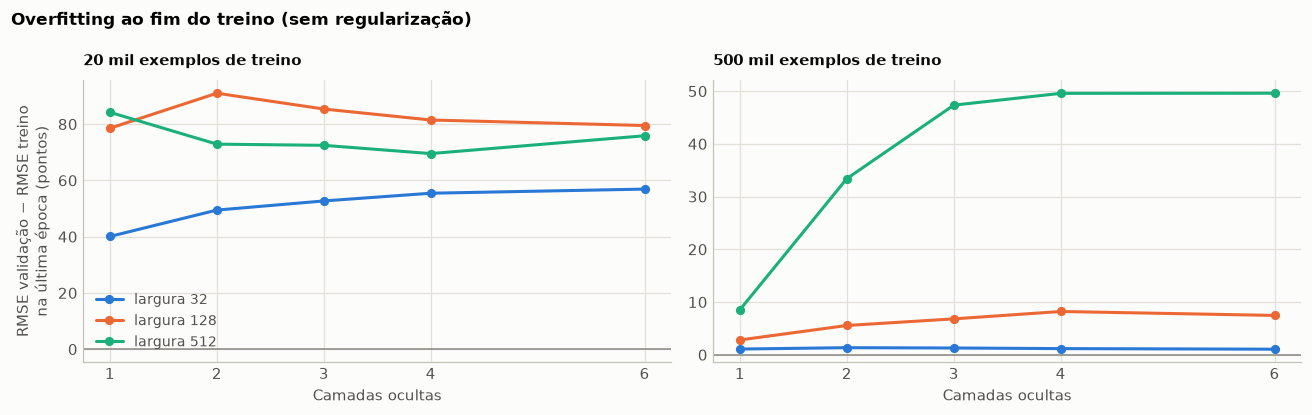

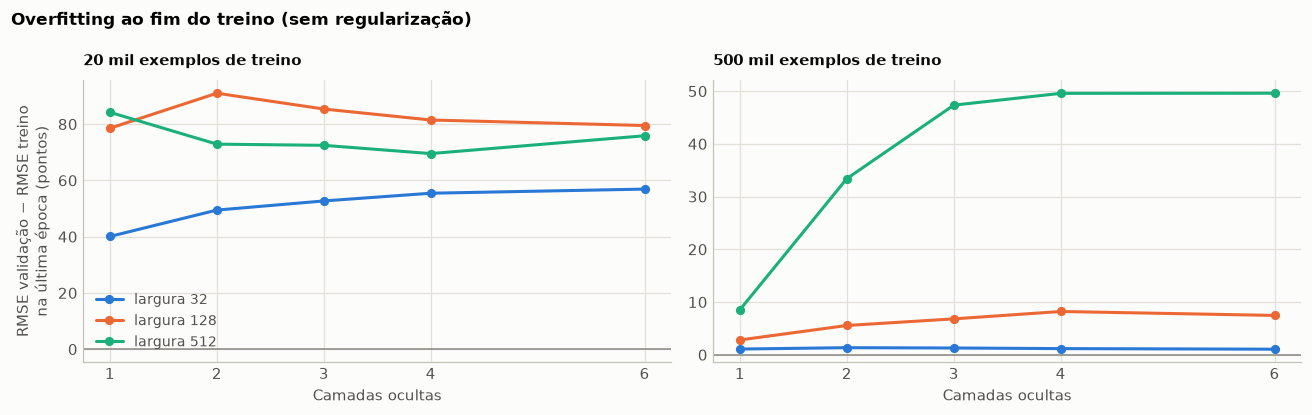

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (esc, titulo) in zip(axes, ESCALAS.items()):
    t = tcap[(tcap["escala"] == esc) & (tcap["profundidade"] > 0)]
    for i, w in enumerate([32, 128, 512]):
        tw = t[t["largura"] == w].sort_values("profundidade")
        ax.plot(tw["profundidade"], tw["gap_final"], marker="o", color=SERIES[i], label=f"largura {w}")
    ax.axhline(0, color=MUTED, linewidth=1)
    ax.set_title(titulo, fontsize=10); ax.set_xlabel("Camadas ocultas"); ax.set_xticks([1, 2, 3, 4, 6])
axes[0].set_ylabel("RMSE validação − RMSE treino\nna última época (pontos)"); axes[0].legend()
fig.suptitle("Overfitting ao fim do treino (sem regularização)", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout(); plots.save(fig, "cap_gap")

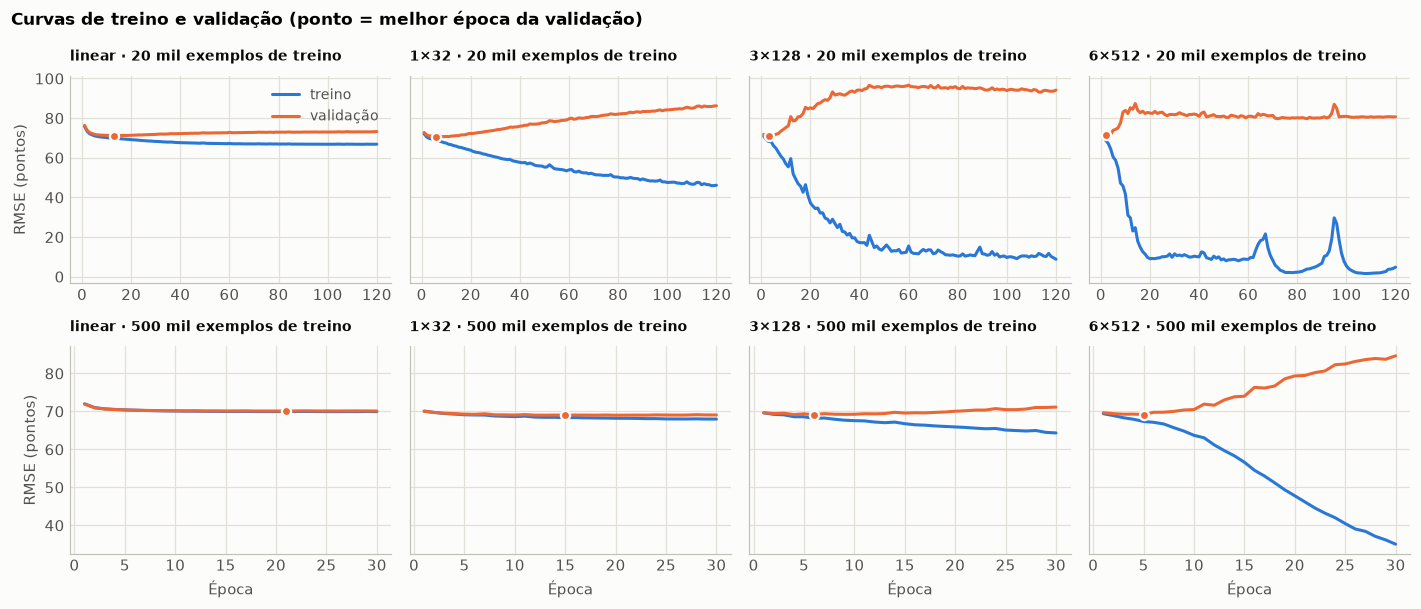

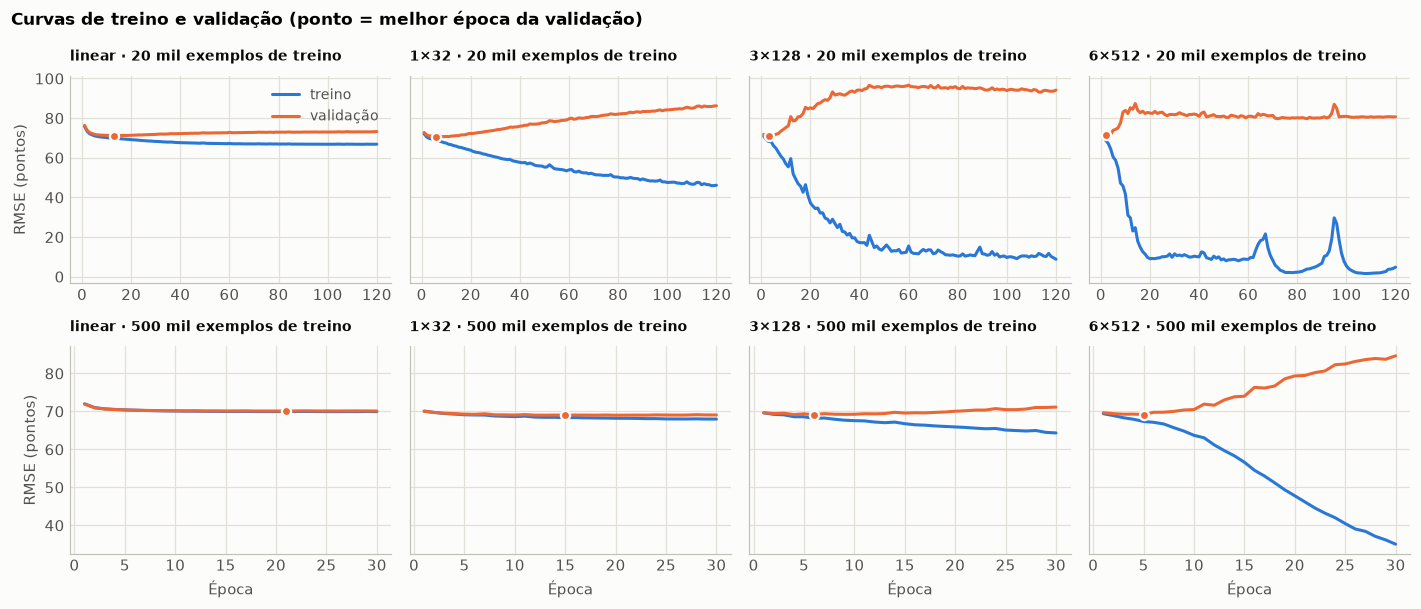

In [6]:
sel = [("d0_w0", "linear"), ("d1_w32", "1×32"), ("d3_w128", "3×128"), ("d6_w512", "6×512")]
fig, axes = plt.subplots(2, 4, figsize=(13, 5.6), sharey="row")
por_nome = {r["name"]: r for r in cap}
for row, esc in enumerate(ESCALAS):
    for col, (k, rot) in enumerate(sel):
        curvas(axes[row, col], por_nome[f"{esc}_{k}"], f"{rot} · {ESCALAS[esc]}")
    axes[row, 0].set_ylabel("RMSE (pontos)")
for ax in axes[1]: ax.set_xlabel("Época")
axes[0, 0].legend()
fig.suptitle("Curvas de treino e validação (ponto = melhor época da validação)", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout(); plots.save(fig, "cap_curvas")

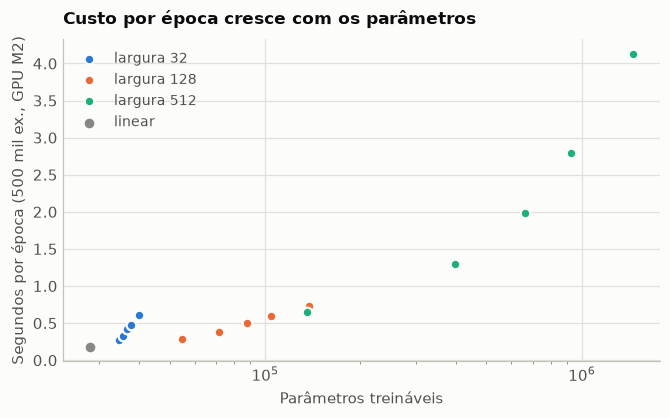

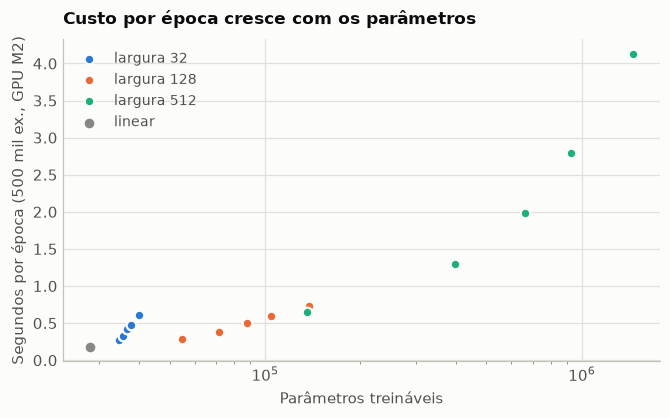

In [7]:
t = tcap[tcap["escala"] == "n500k"]
fig, ax = plt.subplots(figsize=(7, 3.8))
for i, w in enumerate([32, 128, 512]):
    tw = t[t["largura"] == w]
    ax.scatter(tw["n_params"], tw["tempo_epoca_s"], s=40, color=SERIES[i], label=f"largura {w}", edgecolor=plots.SURFACE, linewidth=1.5)
l = t[t["profundidade"] == 0]
ax.scatter(l["n_params"], l["tempo_epoca_s"], s=40, color=MUTED, label="linear")
ax.set_xscale("log"); ax.set_xlabel("Parâmetros treináveis"); ax.set_ylabel("Segundos por época (500 mil ex., GPU M2)")
ax.set_title("Custo por época cresce com os parâmetros"); ax.legend()
plots.save(fig, "cap_custo")

## 2. Regularização (MLP 4×512)

Cada variante muda **uma** coisa em relação a "sem regularização". `val_restaurado` é o RMSE do modelo devolvido: com early stopping, os pesos da melhor época; sem early stopping, os da última.

In [8]:
reg = load_results("regularizacao")
treg = summary_table(reg, ["escala", "variante"])
treg["val_restaurado"] = [r["val"]["rmse"] for r in reg]
ordem = ["sem_regularizacao", "early_stopping", "dropout_0.2", "dropout_0.5", "l2_1e-4", "l2_1e-3",
         "l1_1e-5", "l1_1e-4", "batchnorm", "layernorm", "dropout_l2_es"]
ROT_REG = {"sem_regularizacao": "sem regularização", "early_stopping": "early stopping (paciência 10)", "dropout_0.2": "dropout 0,2",
           "dropout_0.5": "dropout 0,5", "l2_1e-4": "L2 λ = 1e-4", "l2_1e-3": "L2 λ = 1e-3", "l1_1e-5": "L1 λ = 1e-5", "l1_1e-4": "L1 λ = 1e-4",
           "batchnorm": "BatchNorm", "layernorm": "LayerNorm", "dropout_l2_es": "dropout 0,3 + L2 1e-4 + early stopping"}
treg["ordem"] = treg["variante"].map({v: i for i, v in enumerate(ordem)})
treg = treg.sort_values(["escala", "ordem"]).drop(columns="ordem")
treg.to_csv(C.TAB_DIR / "regularizacao.csv", index=False)
treg[["escala", "variante", "melhor_epoca", "val_rmse_melhor", "treino_rmse_final", "val_rmse_final", "gap_final", "val_restaurado", "tempo_treino_s"]]

,escala,variante,melhor_epoca,val_rmse_melhor,treino_rmse_final,val_rmse_final,gap_final,val_restaurado,tempo_treino_s
10,n20k,sem_regularizacao,2,70.97,2.55,79.18,76.63,79.18,60.63
4,n20k,early_stopping,2,70.95,24.91,83.19,58.28,70.95,5.74
1,n20k,dropout_0.2,2,71.10,11.07,77.68,66.61,77.68,64.06
2,n20k,dropout_0.5,4,70.87,28.87,76.19,47.32,76.19,94.67
8,n20k,l2_1e-4,2,70.98,13.76,83.58,69.82,83.58,60.91
7,n20k,l2_1e-3,2,71.16,19.14,89.42,70.28,89.42,57.97
6,n20k,l1_1e-5,2,71.00,13.61,85.03,71.42,85.03,58.02
5,n20k,l1_1e-4,7,71.17,25.49,98.30,72.81,98.30,50.66
0,n20k,batchnorm,2,73.57,9.82,76.58,66.76,76.58,59.08
9,n20k,layernorm,4,70.88,5.75,82.85,77.10,82.85,57.98


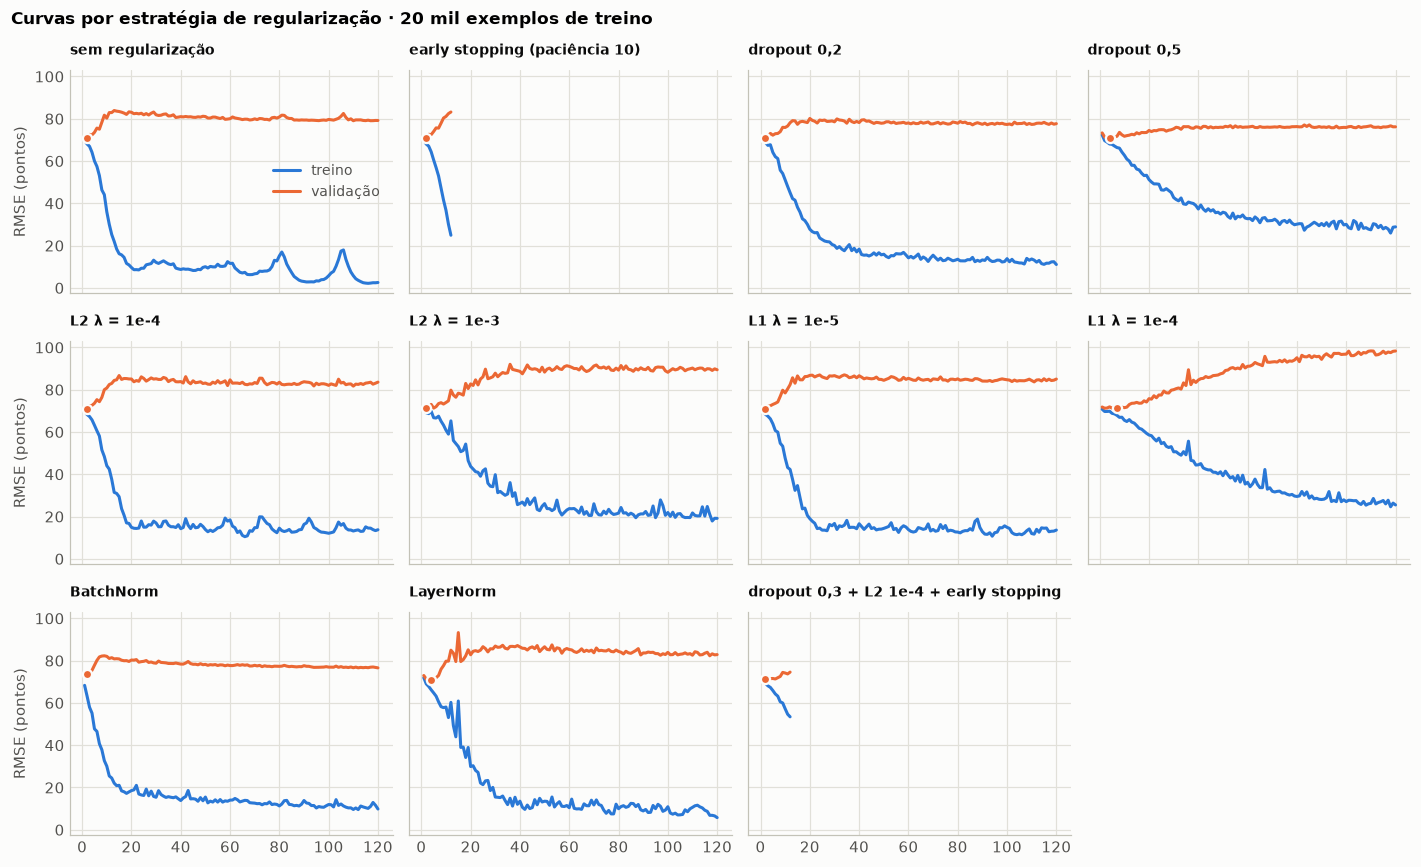

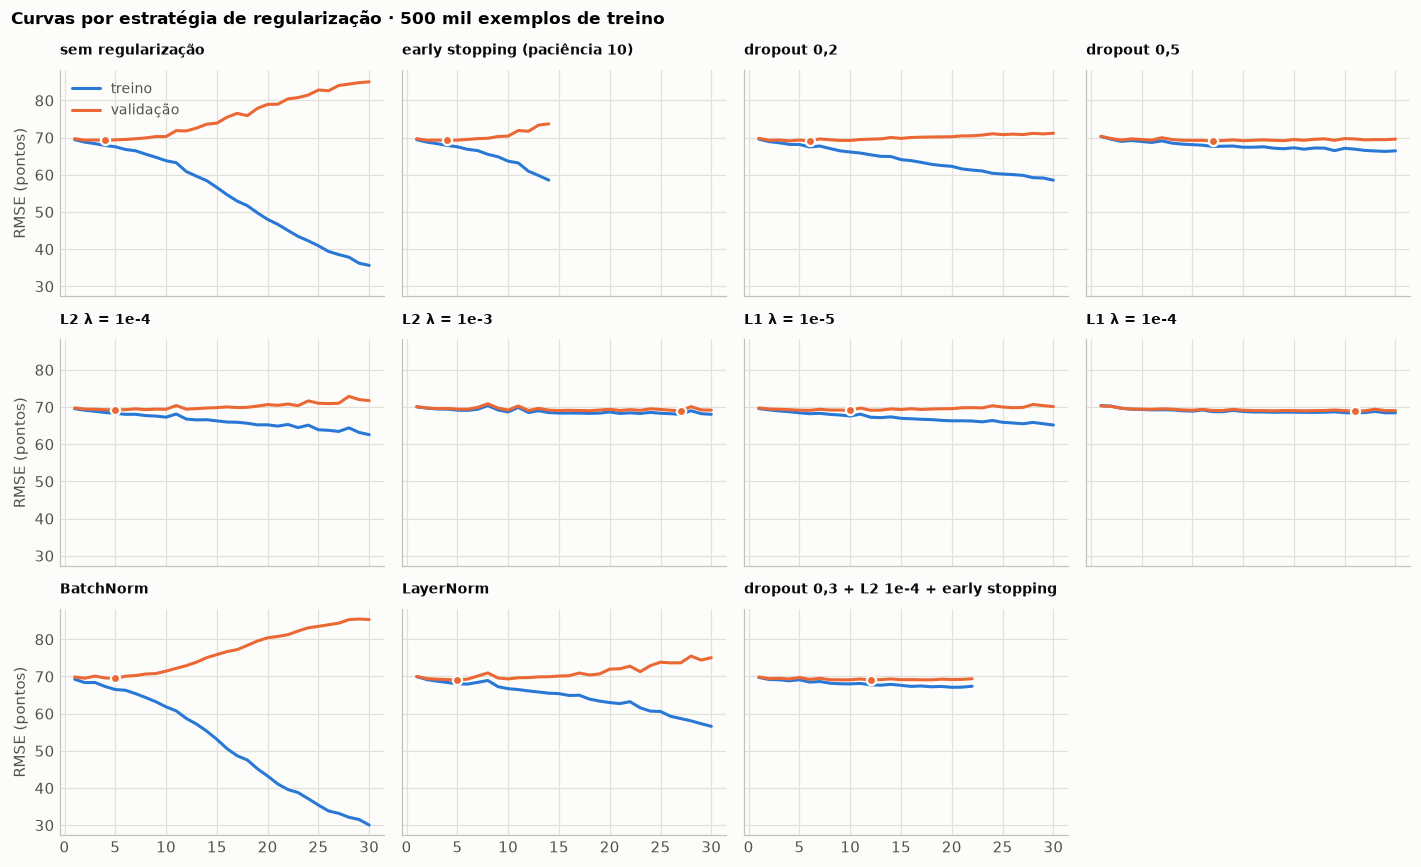

In [9]:
por_nome = {r["name"]: r for r in reg}
for esc in ESCALAS:
    fig, axes = plt.subplots(3, 4, figsize=(13, 8), sharex=True, sharey=True)
    for ax, v in zip(axes.flat, ordem):
        curvas(ax, por_nome[f"{esc}_{v}"], ROT_REG[v])
    axes.flat[-1].axis("off")
    for ax in axes[:, 0]: ax.set_ylabel("RMSE (pontos)")
    axes[0, 0].legend()
    fig.suptitle(f"Curvas por estratégia de regularização · {ESCALAS[esc]}", x=0.01, ha="left", fontsize=11, fontweight="bold")
    fig.tight_layout(); plots.save(fig, f"reg_curvas_{esc}")

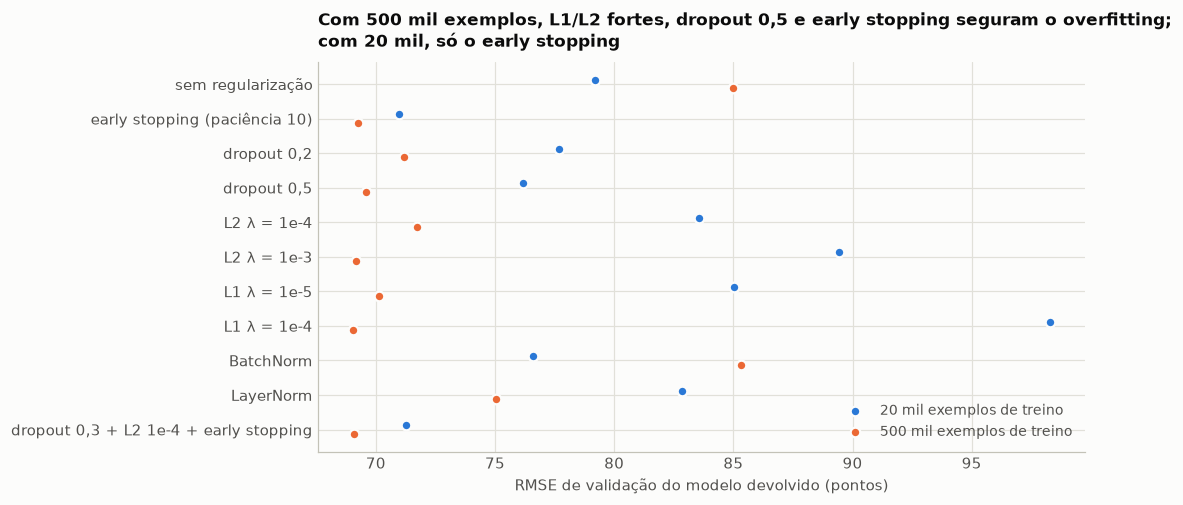

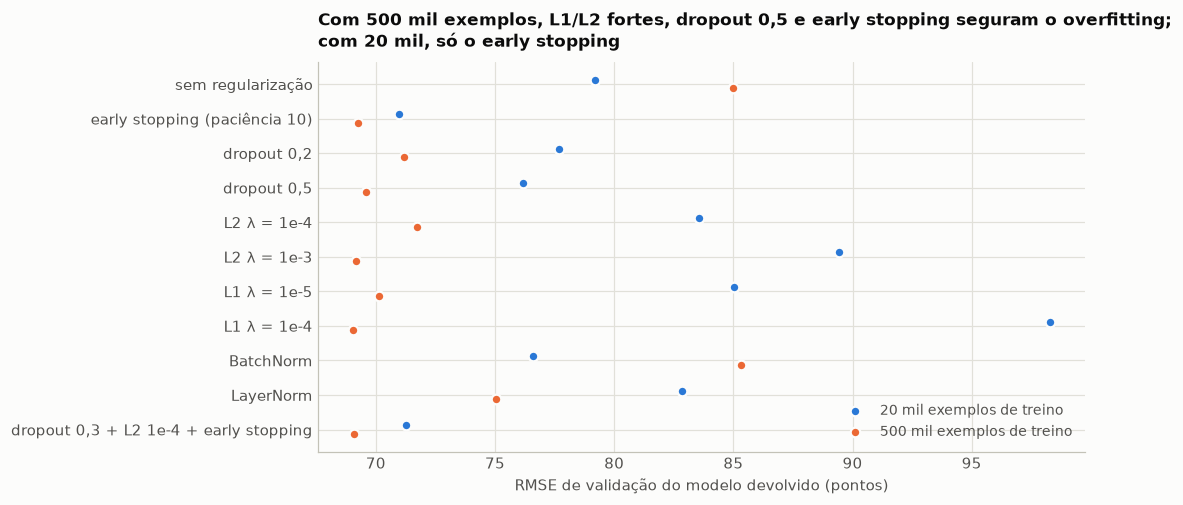

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.6))
y = np.arange(len(ordem))
for i, esc in enumerate(ESCALAS):
    t = treg[treg["escala"] == esc].set_index("variante").reindex(ordem)
    ax.scatter(t["val_restaurado"], y + (i - 0.5) * 0.25, s=40, color=SERIES[i], label=ESCALAS[esc], edgecolor=plots.SURFACE, linewidth=1.5, zorder=3)
ax.set_yticks(y, [ROT_REG[v] for v in ordem]); ax.invert_yaxis()
ax.set_xlabel("RMSE de validação do modelo devolvido (pontos)"); ax.legend(loc="lower right")
ax.set_title("Com 500 mil exemplos, L1/L2 fortes, dropout 0,5 e early stopping seguram o overfitting;\ncom 20 mil, só o early stopping")
plots.save(fig, "reg_resumo")

### 2.1 Diagnóstico: por que L1/L2 não seguraram o overfitting com 20 mil exemplos?

Com 20 mil exemplos, as penalidades deixaram a validação final **pior** que sem regularização. Testamos duas hipóteses (`scripts/03b_diagnostico_l2.py`): (1) o embedding do município, que não é penalizado, compensaria pesos encolhidos → repetir sem embedding; (2) a penalidade somada à perda perde efeito no Adam → trocar por weight decay desacoplado (AdamW).

In [11]:
diag = load_results("diagnostico_l2")
linhas = [{"variante": r["variante"], "embedding": r["config"]["emb_dim"], "otimizador": "AdamW" if r["config"].get("weight_decay", 0) > 0 else "Adam",
           "val_melhor": min(h["val_rmse"] for h in r["history"]), "treino_final": r["history"][-1]["train_rmse"],
           "val_final": r["history"][-1]["val_rmse"]} for r in diag]
for v in ["sem_regularizacao", "l2_1e-3", "l1_1e-4"]:
    r = por_nome[f"n20k_{v}"]
    linhas.append({"variante": v, "embedding": 16, "otimizador": "Adam", "val_melhor": min(h["val_rmse"] for h in r["history"]),
                   "treino_final": r["history"][-1]["train_rmse"], "val_final": r["history"][-1]["val_rmse"]})
tdiag = pd.DataFrame(linhas).sort_values(["embedding", "otimizador", "variante"])
tdiag.to_csv(C.TAB_DIR / "diagnostico_l2.csv", index=False); tdiag

,variante,embedding,otimizador,val_melhor,treino_final,val_final
6,l1_1e-4,0,Adam,70.58,48.11,85.59
7,l2_1e-3,0,Adam,70.63,25.79,90.78
8,sem_regularizacao,0,Adam,70.71,27.23,82.90
0,adamw_wd0.01,0,AdamW,70.71,6.40,79.89
1,adamw_wd0.1,0,AdamW,70.72,22.44,83.09
2,adamw_wd1,0,AdamW,70.79,31.14,81.74
11,l1_1e-4,16,Adam,71.17,25.49,98.30
10,l2_1e-3,16,Adam,71.16,19.14,89.42
9,sem_regularizacao,16,Adam,70.97,2.55,79.18
3,adamw_wd0.01,16,AdamW,70.98,2.72,79.60


## 3. Busca de hiperparâmetros (Optuna)

In [12]:
study = optuna.load_study(study_name="enem_mlp", storage=f"sqlite:///{C.OUTPUTS / 'optuna.db'}")
tr = study.trials_dataframe(attrs=("number", "value", "state", "params", "user_attrs", "duration"))
tr["duracao_s"] = tr["duration"].dt.total_seconds()
print(tr["state"].value_counts().to_string())
print(f"tempo total da busca: {tr['duracao_s'].sum()/60:.0f} min; melhor trial: #{study.best_trial.number} com RMSE {study.best_value:.2f}")
comp = tr[tr["state"] == "COMPLETE"].sort_values("value")
cols = ["number", "value", "user_attrs_val_r2", "user_attrs_train_rmse", "user_attrs_hidden", "params_ativacao", "params_dropout",
        "params_normalizacao", "params_l2", "params_lr", "params_batch_size", "params_emb_municipio", "user_attrs_n_params", "duracao_s"]
comp[cols].head(10)

state
COMPLETE    36
PRUNED      24
tempo total da busca: 25 min; melhor trial: #33 com RMSE 68.84


,number,value,user_attrs_val_r2,user_attrs_train_rmse,user_attrs_hidden,params_ativacao,params_dropout,params_normalizacao,params_l2,params_lr,params_batch_size,params_emb_municipio,user_attrs_n_params,duracao_s
33,33,68.84,0.38,68.09,"[658, 658]",silu,0.46,layer,0.00,0.00,1024,16,"602,965.00",62.68
58,58,68.85,0.38,68.00,[296],silu,0.34,layer,0.00,0.00,1024,16,"90,921.00",14.54
40,40,68.86,0.38,68.10,[234],silu,0.44,layer,0.00,0.00,1024,16,"77,715.00",15.10
52,52,68.86,0.38,68.15,"[296, 296]",silu,0.49,layer,0.00,0.00,1024,16,"179,425.00",26.37
21,21,68.86,0.38,68.13,"[420, 210, 105]",silu,0.45,layer,0.00,0.00,1024,16,"228,213.00",39.61
59,59,68.87,0.38,68.11,[227],silu,0.37,layer,0.00,0.00,1024,16,"76,224.00",14.34
54,54,68.87,0.38,68.30,"[282, 282]",silu,0.44,layer,0.00,0.00,1024,16,"168,309.00",16.28
38,38,68.88,0.38,67.87,"[475, 475, 475]",silu,0.37,layer,0.00,0.00,1024,16,"583,148.00",51.77
42,42,68.89,0.38,68.09,"[348, 348, 348]",silu,0.39,layer,0.00,0.00,1024,16,"346,293.00",45.64
28,28,68.89,0.38,68.25,"[382, 382]",silu,0.38,layer,0.00,0.00,1024,16,"256,309.00",24.49


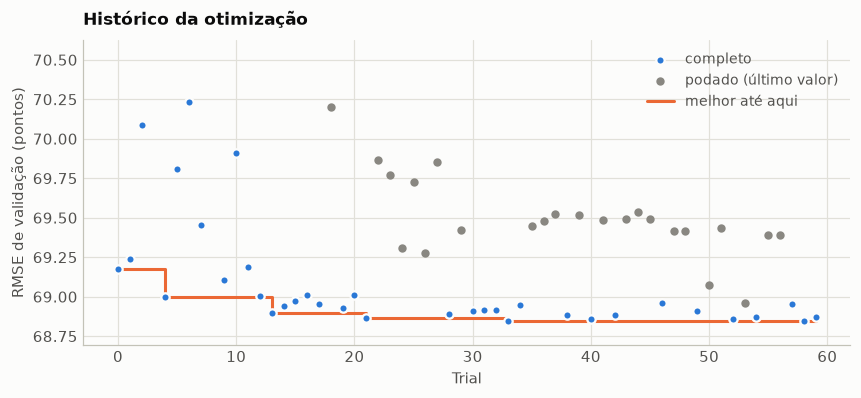

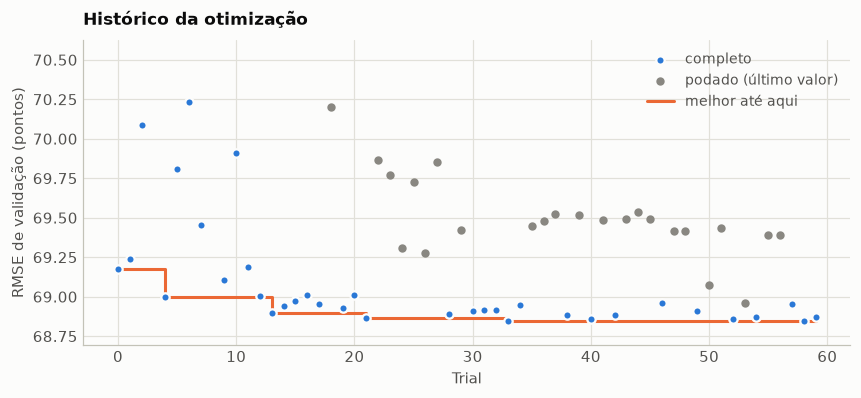

In [13]:
fig, ax = plt.subplots(figsize=(9, 3.6))
okm = tr["state"] == "COMPLETE"
ax.scatter(tr.loc[okm, "number"], tr.loc[okm, "value"], s=30, color=SERIES[0], label="completo", edgecolor=plots.SURFACE, linewidth=1.5, zorder=3)
pr = tr[tr["state"] == "PRUNED"]
# trial podado: último valor reportado
ultimo = {t.number: list(t.intermediate_values.values())[-1] for t in study.trials if t.state.name == "PRUNED" and t.intermediate_values}
ax.scatter(list(ultimo), list(ultimo.values()), s=30, color=MUTED, label="podado (último valor)", zorder=2)
melhor = tr.loc[okm].set_index("number")["value"].cummin()
ax.step(melhor.index, melhor.values, where="post", color=SERIES[1], label="melhor até aqui")
ax.set_ylim(tr.loc[okm, "value"].min() - 0.15, tr.loc[okm, "value"].quantile(0.95) + 0.5)
ax.set_xlabel("Trial"); ax.set_ylabel("RMSE de validação (pontos)"); ax.legend()
ax.set_title("Histórico da otimização"); plots.save(fig, "optuna_historico")

l2              0.23
dropout         0.21
emb_municipio   0.14
normalizacao    0.14
lr              0.12
ativacao        0.06
batch_size      0.05
largura         0.03
n_camadas       0.02
formato         0.00
dtype: float64

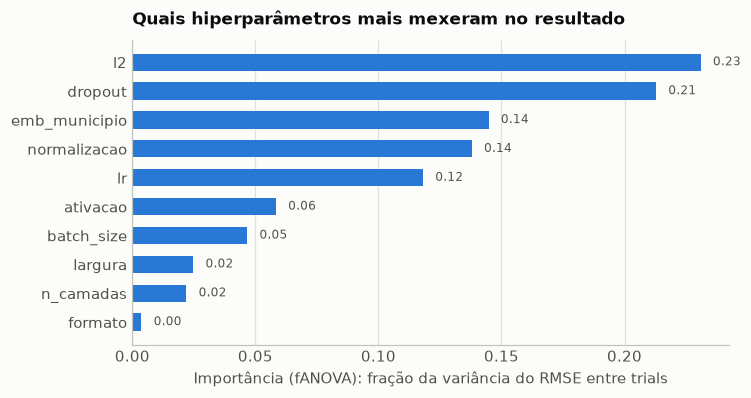

In [14]:
imp = optuna.importance.get_param_importances(study, evaluator=optuna.importance.FanovaImportanceEvaluator(seed=C.SEED))
imp = pd.Series(imp).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(imp.index, imp.values, height=0.6, color=SERIES[0])
for i, v in enumerate(imp.values): ax.text(v + 0.005, i, f"{v:.2f}", va="center", fontsize=8, color=INK_2)
ax.set_xlabel("Importância (fANOVA): fração da variância do RMSE entre trials"); ax.grid(axis="y", visible=False)
ax.set_title("Quais hiperparâmetros mais mexeram no resultado"); plots.save(fig, "optuna_importancia")
imp.sort_values(ascending=False).round(3)

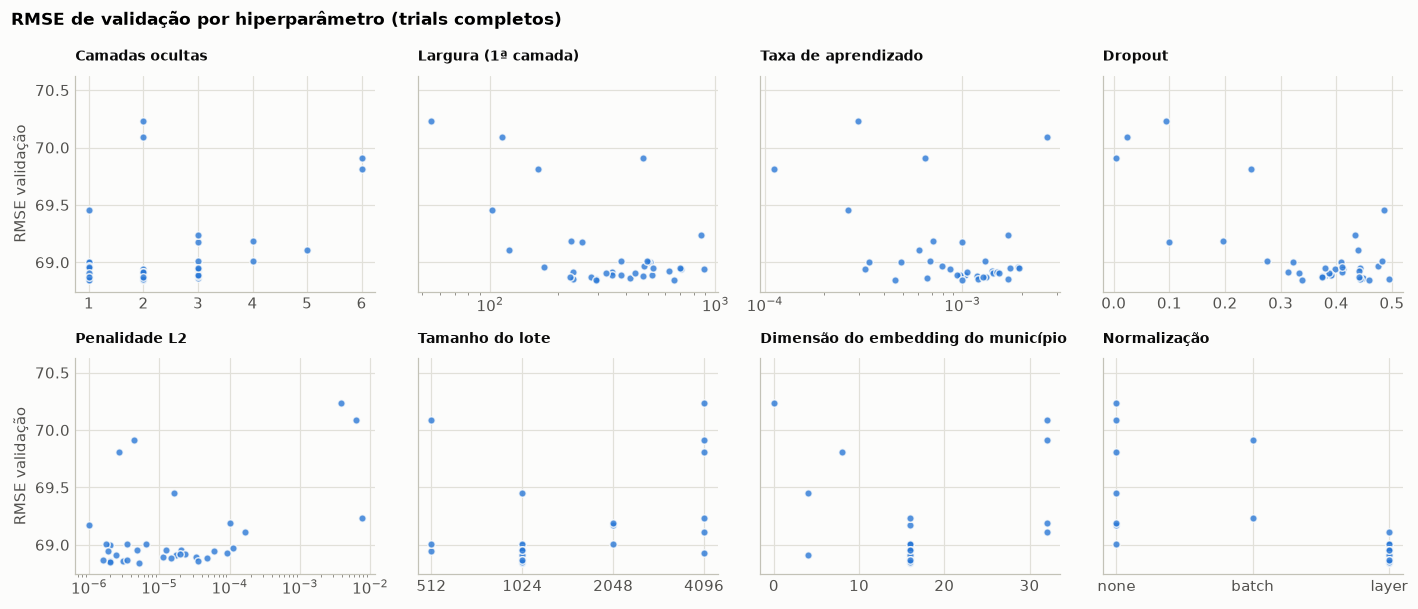

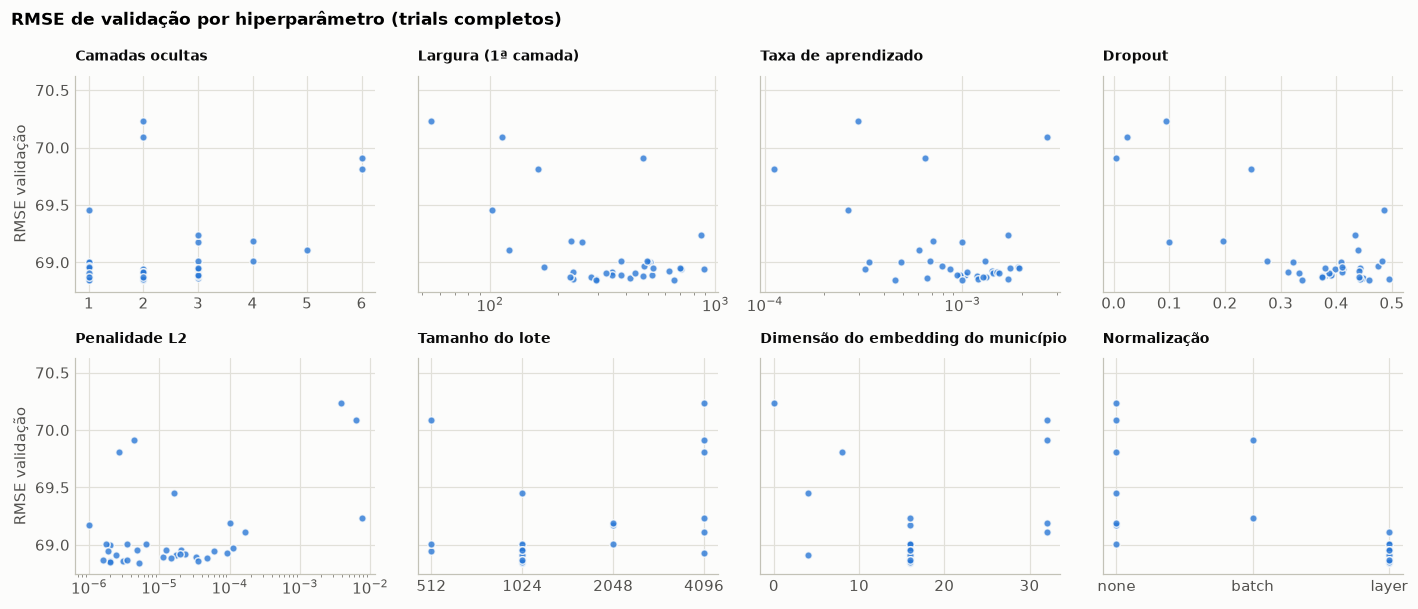

In [15]:
num = [("params_n_camadas", "Camadas ocultas", False), ("params_largura", "Largura (1ª camada)", True), ("params_lr", "Taxa de aprendizado", True),
       ("params_dropout", "Dropout", False), ("params_l2", "Penalidade L2", True), ("params_batch_size", "Tamanho do lote", False),
       ("params_emb_municipio", "Dimensão do embedding do município", False), ("params_normalizacao", "Normalização", False)]
c = tr[okm]
fig, axes = plt.subplots(2, 4, figsize=(13, 5.6), sharey=True)
for ax, (col, rot, logx) in zip(axes.flat, num):
    x = c[col].astype(str) if col == "params_batch_size" else c[col]
    if col == "params_batch_size":
        cats = ["512", "1024", "2048", "4096"]; x = x.map({k: i for i, k in enumerate(cats)}); ax.set_xticks(range(len(cats)), cats)
    elif x.dtype == object:
        cats = sorted(x.unique()); x = x.map({k: i for i, k in enumerate(cats)}); ax.set_xticks(range(len(cats)), cats)
    ax.scatter(x, c["value"], s=24, color=SERIES[0], alpha=0.8, edgecolor=plots.SURFACE, linewidth=1)
    if logx: ax.set_xscale("log")
    ax.set_title(rot, fontsize=9)
for ax in axes[:, 0]: ax.set_ylabel("RMSE validação")
axes[0, 0].set_ylim(top=c["value"].quantile(0.95) + 0.5)
fig.suptitle("RMSE de validação por hiperparâmetro (trials completos)", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout(); plots.save(fig, "optuna_slices")

,trial,val_rmse_optuna,params,hidden
A_melhor,33,68.84,"{'n_camadas': 2, 'largura': 658, 'formato': 'c...","[658, 658]"
B_compacta,46,68.96,"{'n_camadas': 1, 'largura': 173, 'formato': 'c...",[173]
C_contraste,16,69.01,"{'n_camadas': 4, 'largura': 380, 'formato': 'f...","[380, 190, 95, 47]"


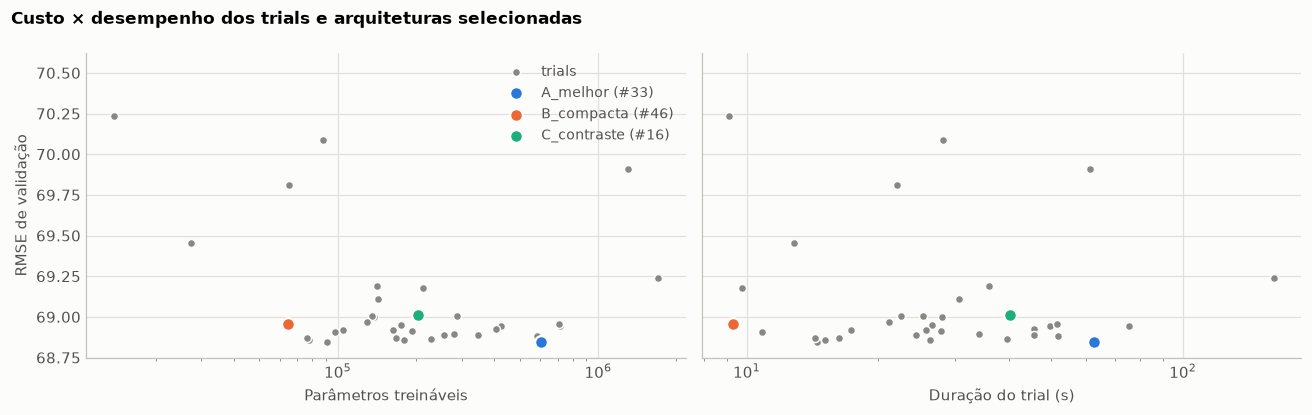

In [16]:
sel = json.loads((C.TAB_DIR / "selecao_arquiteturas.json").read_text())
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (col, rot) in zip(axes, [("user_attrs_n_params", "Parâmetros treináveis"), ("duracao_s", "Duração do trial (s)")]):
    ax.scatter(c[col], c["value"], s=28, color=MUTED, edgecolor=plots.SURFACE, linewidth=1, label="trials")
    for i, (nome, m) in enumerate(sel.items()):
        r = c[c["number"] == m["trial"]]
        ax.scatter(r[col], r["value"], s=70, color=SERIES[i], edgecolor=plots.SURFACE, linewidth=1.5, zorder=3, label=f"{nome} (#{m['trial']})")
    ax.set_xscale("log"); ax.set_xlabel(rot)
axes[0].set_ylabel("RMSE de validação"); axes[0].set_ylim(top=c["value"].quantile(0.95) + 0.5); axes[0].legend()
fig.suptitle("Custo × desempenho dos trials e arquiteturas selecionadas", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout(); plots.save(fig, "optuna_pareto")
pd.DataFrame(sel).T

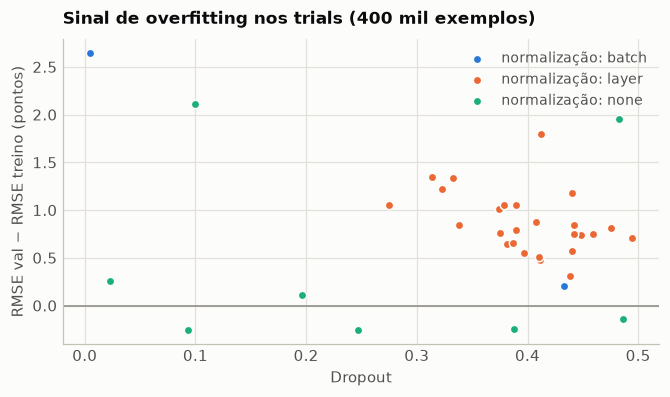

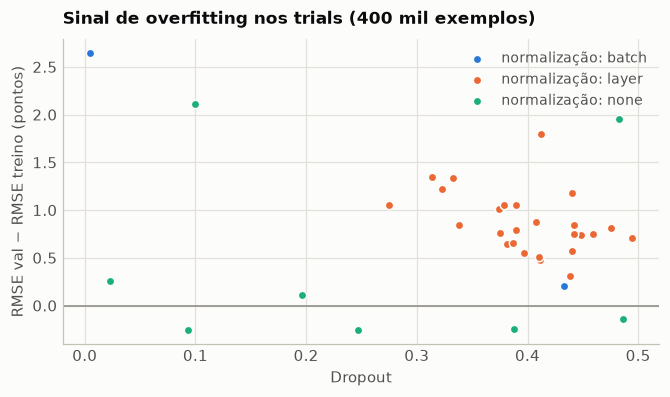

In [17]:
c2 = c.assign(gap=c["value"] - c["user_attrs_train_rmse"])
fig, ax = plt.subplots(figsize=(7, 3.6))
for i, (k, g) in enumerate(c2.groupby("params_normalizacao")):
    ax.scatter(g["params_dropout"], g["gap"], s=30, color=SERIES[i], label=f"normalização: {k}", edgecolor=plots.SURFACE, linewidth=1)
ax.axhline(0, color=MUTED, linewidth=1)
ax.set_xlabel("Dropout"); ax.set_ylabel("RMSE val − RMSE treino (pontos)"); ax.legend()
ax.set_title("Sinal de overfitting nos trials (400 mil exemplos)"); plots.save(fig, "optuna_gap")

## 4. Avaliação final

Arquiteturas retreinadas no **treino completo** (1,87 mi), com early stopping na validação, 3 sementes cada. **teste-2022** = 10% de 2022 nunca vistos; **teste-2023** = todos os 2,66 mi participantes de 2023 (ano seguinte).

In [18]:
fr = pd.read_csv(C.TAB_DIR / "resultados_finais_por_seed.csv")
agg = fr.groupby(["modelo", "split"]).agg(rmse=("rmse", "mean"), rmse_dp=("rmse", "std"), mae=("mae", "mean"), r2=("r2", "mean"),
        vies=("bias", "mean"), n_params=("n_params", "first"), treino_s=("train_time_s", "mean"),
        inferencia_100k_s=("infer_time_100k_s", "mean"), melhor_epoca=("best_epoch", "mean")).reset_index()
ordem_m = ["media_treino", "linear", "A_melhor", "B_compacta", "C_contraste"]
agg["o"] = agg["modelo"].map({m: i for i, m in enumerate(ordem_m)})
agg = agg.sort_values(["split", "o"]).drop(columns="o")
agg.to_csv(C.TAB_DIR / "resultados_finais.csv", index=False)
tab = agg.pivot(index="modelo", columns="split", values=["rmse", "mae", "r2"]).reindex(ordem_m)
tab.columns = [f"{m}_{s}" for m, s in tab.columns]
custo = agg[agg["split"] == "test23"].set_index("modelo")[["n_params", "treino_s", "inferencia_100k_s", "melhor_epoca"]]
final = tab[[f"{m}_{s}" for s in ["val", "test22", "test23"] for m in ["rmse", "mae", "r2"]]].join(custo)
final.to_csv(C.TAB_DIR / "tabela_final.csv"); final

,rmse_val,mae_val,r2_val,rmse_test22,mae_test22,r2_test22,rmse_test23,mae_test23,r2_test23,n_params,treino_s,inferencia_100k_s,melhor_epoca
modelo,,,,,,,,,,,,,
media_treino,87.86,69.94,-0.00,87.77,69.93,0.00,92.97,75.14,-0.00,1,NaN,NaN,NaN
linear,70.16,55.17,0.36,70.18,55.23,0.36,74.77,59.63,0.35,28082,10.29,0.01,24.33
A_melhor,68.40,53.60,0.39,68.45,53.69,0.39,72.92,57.99,0.38,602965,541.76,0.16,38.00
B_compacta,68.49,53.69,0.39,68.53,53.78,0.39,73.05,58.12,0.38,64722,141.41,0.02,37.33
C_contraste,68.47,53.66,0.39,68.54,53.77,0.39,73.03,58.09,0.38,204191,342.19,0.06,23.00


In [19]:
print("Desvio-padrão do RMSE entre sementes (pontos):")
agg.pivot(index="modelo", columns="split", values="rmse_dp").reindex(ordem_m).round(3)

Desvio-padrão do RMSE entre sementes (pontos):


split,test22,test23,val
modelo,,,
media_treino,NaN,NaN,NaN
linear,0.00,0.01,0.00
A_melhor,0.01,0.01,0.01
B_compacta,0.01,0.00,0.01
C_contraste,0.01,0.04,0.01


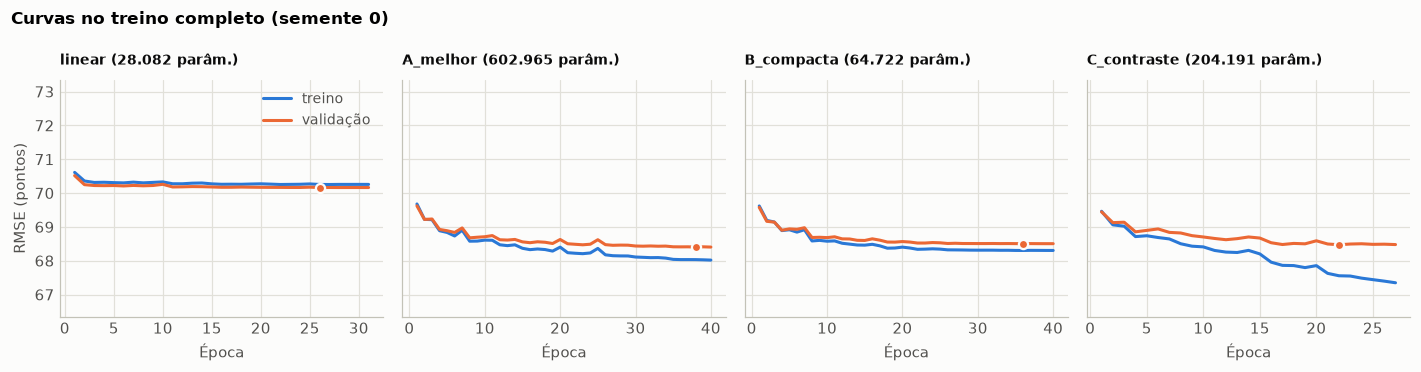

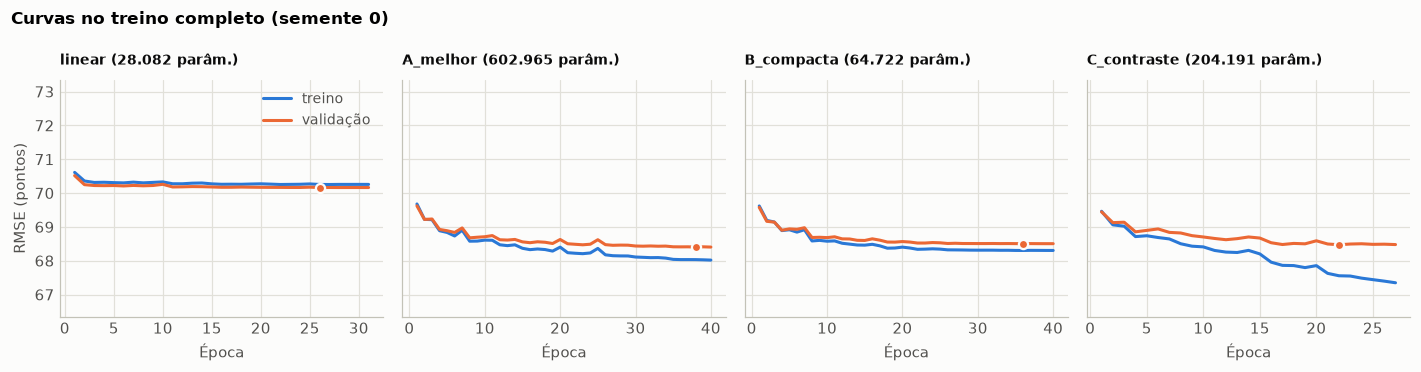

In [20]:
fin = {r["name"]: r for r in load_results("finais")}
nomes_m = ["linear", "A_melhor", "B_compacta", "C_contraste"]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), sharey=True)
for ax, m in zip(axes, nomes_m):
    curvas(ax, fin[f"{m}_seed0"], f"{m} ({fin[f'{m}_seed0']['n_params']:,} parâm.)".replace(",", "."))
    ax.set_xlabel("Época")
axes[0].set_ylabel("RMSE (pontos)"); axes[0].legend()
lo = min(min(h["train_rmse"] for h in fin[f"{m}_seed0"]["history"]) for m in nomes_m)
axes[0].set_ylim(lo - 1, lo + 6)
fig.suptitle("Curvas no treino completo (semente 0)", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout(); plots.save(fig, "final_curvas")

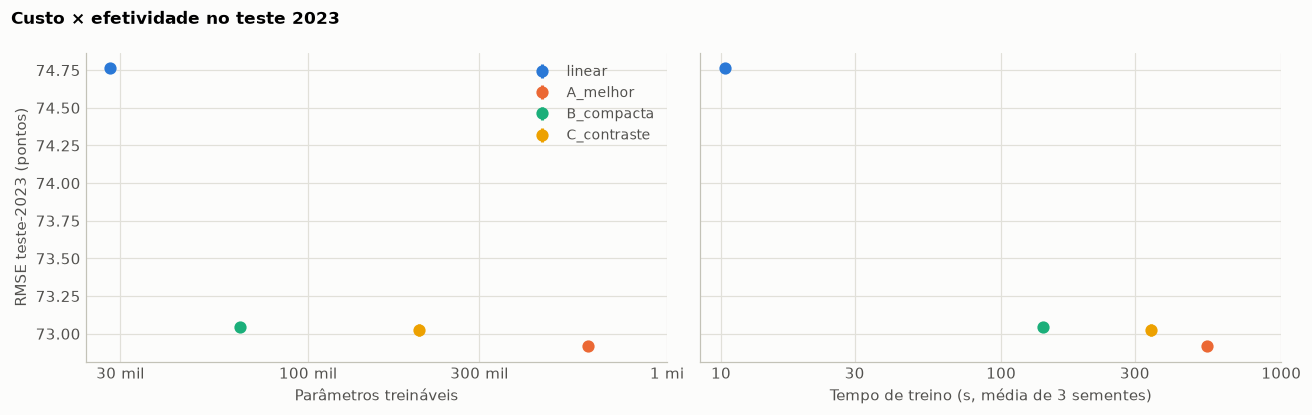

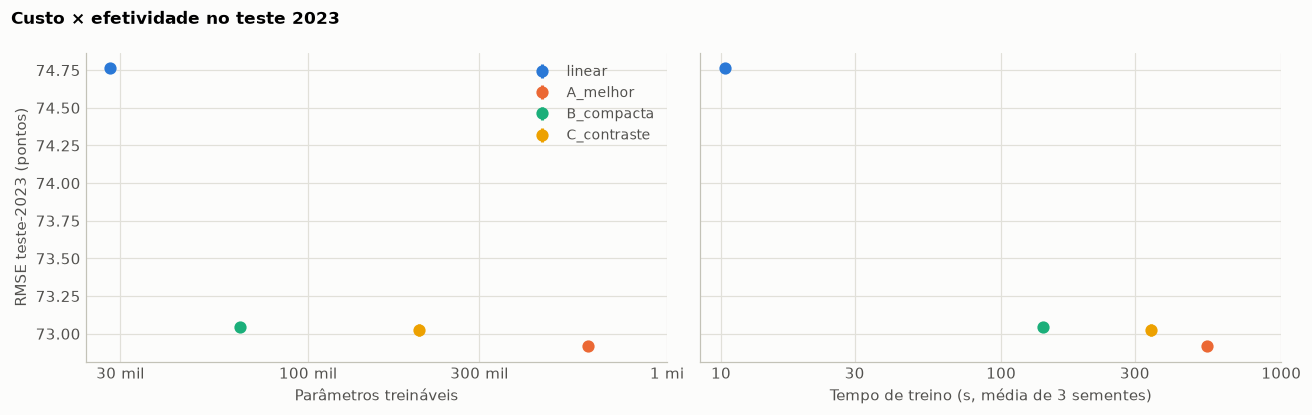

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
t23 = agg[(agg["split"] == "test23") & (agg["modelo"] != "media_treino")].set_index("modelo").reindex(nomes_m)
for ax, (col, rot) in zip(axes, [("n_params", "Parâmetros treináveis"), ("treino_s", "Tempo de treino (s, média de 3 sementes)")]):
    for i, (m, r) in enumerate(t23.iterrows()):
        ax.errorbar(r[col], r["rmse"], yerr=r["rmse_dp"], fmt="o", color=SERIES[i], markersize=7, label=m, capsize=0)
    ax.set_xscale("log"); ax.set_xlabel(rot); ax.minorticks_off()
    ticks = [3e4, 1e5, 3e5, 1e6] if col == "n_params" else [10, 30, 100, 300, 1000]
    ax.set_xticks(ticks, [f"{t/1000:.0f} mil" if col == "n_params" and t < 1e6 else ("1 mi" if col == "n_params" else f"{t:.0f}") for t in ticks])
axes[0].set_ylabel("RMSE teste-2023 (pontos)"); axes[0].legend()
fig.suptitle("Custo × efetividade no teste 2023", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout(); plots.save(fig, "final_custo_efetividade")

## 5. Análise de erros (melhor modelo na validação, teste-2023)

In [22]:
melhor = agg[(agg["split"] == "val") & agg["modelo"].isin(["A_melhor", "B_compacta", "C_contraste"])].sort_values("rmse")["modelo"].iloc[0]
print("modelo analisado:", melhor)
meta = load_meta("test23")
pred = pd.read_parquet(C.OUTPUTS / "predicoes_test23.parquet")
meta["pred"] = pred[melhor].values
meta["pred_linear"] = pred["linear"].values
meta["erro"] = meta["pred"] - meta[C.TARGET]
print(f"RMSE {np.sqrt((meta['erro']**2).mean()):.2f} | MAE {meta['erro'].abs().mean():.2f} | viés {meta['erro'].mean():.2f}")
print(f"faixa das predições: {meta['pred'].min():.0f}–{meta['pred'].max():.0f} (real: {meta[C.TARGET].min():.0f}–{meta[C.TARGET].max():.0f})")
print(f"desvio das predições {meta['pred'].std():.1f} vs desvio real {meta[C.TARGET].std():.1f}")
resumo_erro = {"modelo": melhor, "rmse": float(np.sqrt((meta['erro']**2).mean())), "mae": float(meta['erro'].abs().mean()),
               "vies": float(meta['erro'].mean()), "std_pred": float(meta['pred'].std()), "std_real": float(meta[C.TARGET].std()),
               "pred_min": float(meta['pred'].min()), "pred_max": float(meta['pred'].max()),
               "frac_erro_abs_lt_50": float((meta['erro'].abs() < 50).mean()), "frac_erro_abs_gt_100": float((meta['erro'].abs() > 100).mean())}
_ = (C.TAB_DIR / "analise_erros.json").write_text(json.dumps(resumo_erro, indent=1))

modelo analisado: A_melhor


RMSE 72.91 | MAE 57.97 | viés -2.35
faixa das predições: 390–727 (real: 246–863)
desvio das predições 54.8 vs desvio real 93.0


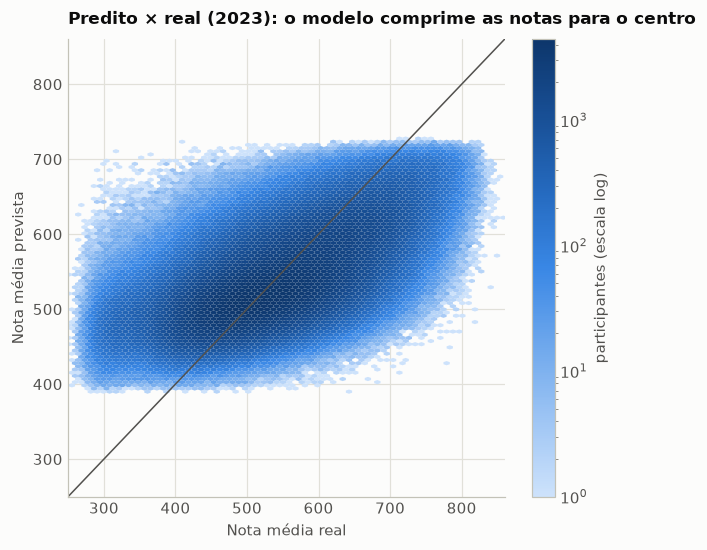

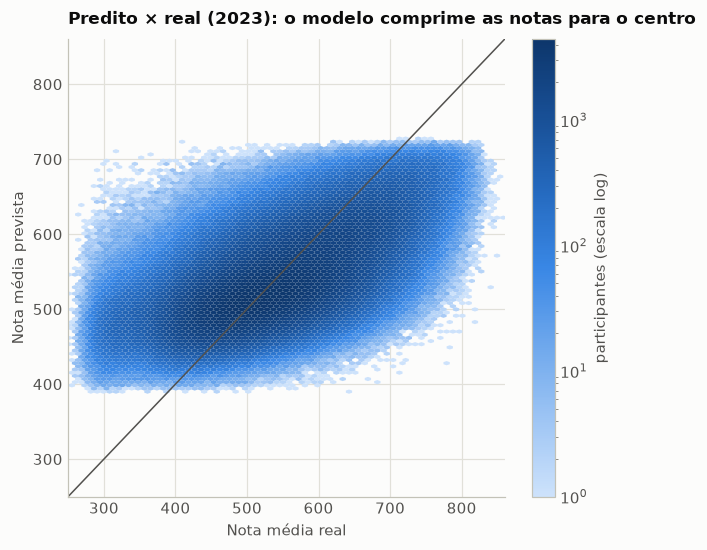

In [23]:
fig, ax = plt.subplots(figsize=(6.4, 5.4))
hb = ax.hexbin(meta[C.TARGET], meta["pred"], gridsize=70, cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list("b", plots.BLUE_RAMP),
               mincnt=1, bins="log", linewidths=0)
lims = [250, 860]; ax.plot(lims, lims, color=INK_2, linewidth=1)
ax.set_xlim(lims); ax.set_ylim(lims); ax.set_xlabel("Nota média real"); ax.set_ylabel("Nota média prevista")
fig.colorbar(hb, ax=ax, label="participantes (escala log)")
ax.set_title("Predito × real (2023): o modelo comprime as notas para o centro"); plots.save(fig, "erro_hexbin")

,nota_real,prevista,vies,mae
decil_real,,,,
D1,383.30,492.90,109.60,109.60
D2,445.20,504.60,59.40,60.40
D3,477.00,513.70,36.80,42.20
D4,503.40,522.00,18.70,33.70
D5,528.00,530.00,2.00,32.60
D6,552.30,538.60,-13.70,36.90
D7,578.10,548.40,-29.70,44.70
D8,607.20,561.00,-46.10,54.90
D9,643.50,578.40,-65.10,68.90


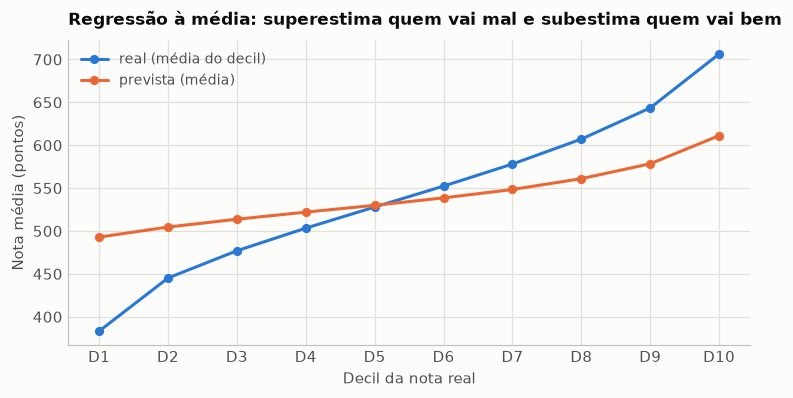

In [24]:
meta["decil_real"] = pd.qcut(meta[C.TARGET], 10, labels=[f"D{i}" for i in range(1, 11)])
dec = meta.groupby("decil_real", observed=True).agg(nota_real=(C.TARGET, "mean"), prevista=("pred", "mean"),
        vies=("erro", "mean"), mae=("erro", lambda e: e.abs().mean()))
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(dec))
ax.plot(x, dec["nota_real"], marker="o", color=SERIES[0], label="real (média do decil)")
ax.plot(x, dec["prevista"], marker="o", color=SERIES[1], label="prevista (média)")
ax.set_xticks(x, dec.index); ax.set_xlabel("Decil da nota real"); ax.set_ylabel("Nota média (pontos)"); ax.legend()
ax.set_title("Regressão à média: superestima quem vai mal e subestima quem vai bem"); plots.save(fig, "erro_decis")
dec.to_csv(C.TAB_DIR / "erro_decis.csv"); dec.round(1)

In [25]:
def por_grupo(col, mapa=None):
    g = meta.groupby(col, observed=True).agg(n=("erro", "size"), real=(C.TARGET, "mean"), vies=("erro", "mean"),
                                             rmse=("erro", lambda e: np.sqrt((e**2).mean())))
    if mapa: g.index = [mapa.get(i, i) for i in g.index]
    return g
grupos = {
  "Tipo de escola": por_grupo("TP_ESCOLA", {1: "não respondeu", 2: "pública", 3: "privada"}),
  "Sexo (não usado no modelo)": por_grupo("TP_SEXO", {"F": "feminino", "M": "masculino"}),
  "Cor/raça (não usada no modelo)": por_grupo("TP_COR_RACA", {0: "não declarado", 1: "branca", 2: "preta", 3: "parda", 4: "amarela", 5: "indígena", 6: "sem informação"}),
  "Treineiro": por_grupo("IN_TREINEIRO", {0: "não", 1: "sim"}),
  "Redação": meta.assign(r0=np.where(meta["NU_NOTA_REDACAO"] == 0, "nota 0", "nota > 0")).pipe(lambda m: m.groupby("r0").agg(
        n=("erro", "size"), real=(C.TARGET, "mean"), vies=("erro", "mean"), rmse=("erro", lambda e: np.sqrt((e**2).mean())))),
}
gtab = pd.concat(grupos, names=["grupo", "categoria"])
gtab.to_csv(C.TAB_DIR / "erro_por_grupo.csv"); gtab.round(1)

n   real   vies   rmse
grupo                          categoria                                  
Tipo de escola                 não respondeu  1614715 544.90  -1.00  72.60
                               pública         823248 517.60  -3.00  73.50
                               privada         220800 616.70  -9.80  73.20
Sexo (não usado no modelo)     feminino       1632353 539.70  -3.00  70.20
                               masculino      1026410 546.70  -1.40  77.10
Cor/raça (não usada no modelo) não declarado    32946 541.50  -3.50  77.00
                               branca         1146256 570.60  -9.70  73.40
                               preta           314240 514.20   7.10  70.90
                               parda          1108782 522.30   2.20  72.90
                               amarela          42333 538.20  -0.10  73.10
                               indígena         14206 481.40  19.80  72.40
Treineiro                      não            2152164 542.20  -2.10  73.00
                               sim             506599 543.20  -3.50  72.70
Redação                        nota 0           89573 358.30 143.40 151.20
                               nota > 0       2569190 548.80  -7.40  68.60

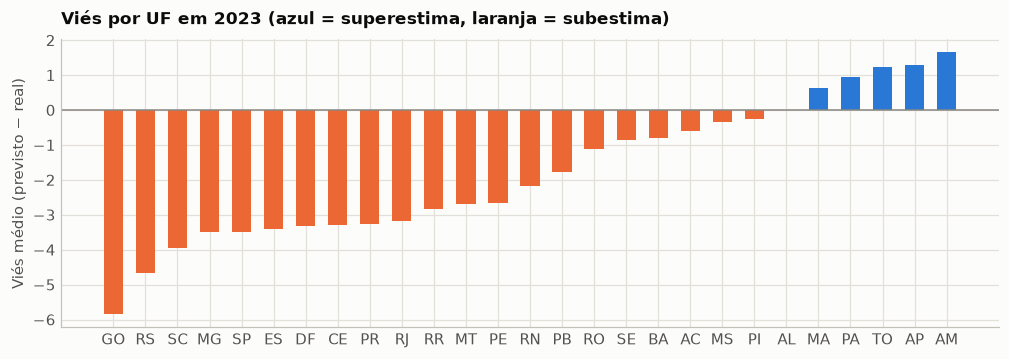

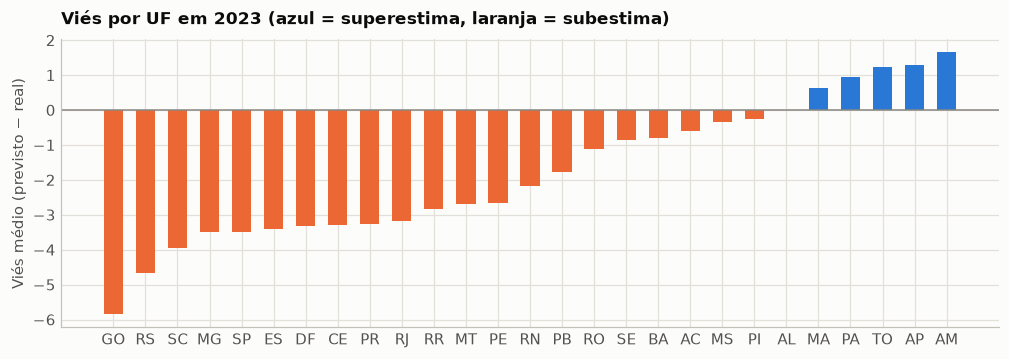

In [26]:
uf = por_grupo("SG_UF_PROVA").sort_values("vies"); uf.to_csv(C.TAB_DIR / "erro_uf.csv")
fig, ax = plt.subplots(figsize=(11, 3.4))
cores = [SERIES[0] if v >= 0 else SERIES[1] for v in uf["vies"]]
ax.bar(uf.index, uf["vies"], width=0.6, color=cores)
ax.axhline(0, color=MUTED, linewidth=1); ax.set_ylabel("Viés médio (previsto − real)")
ax.set_title("Viés por UF em 2023 (azul = superestima, laranja = subestima)"); plots.save(fig, "erro_uf")

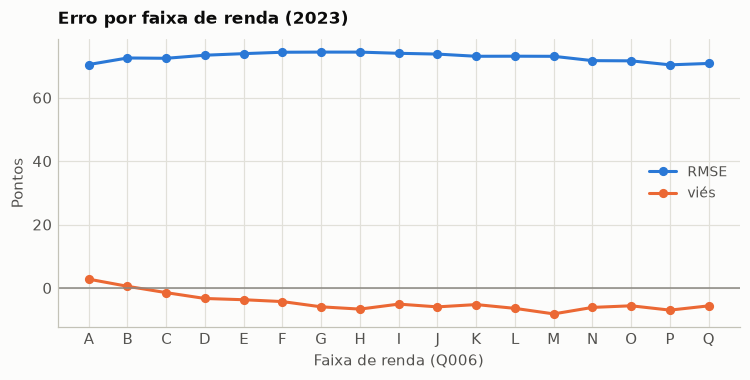

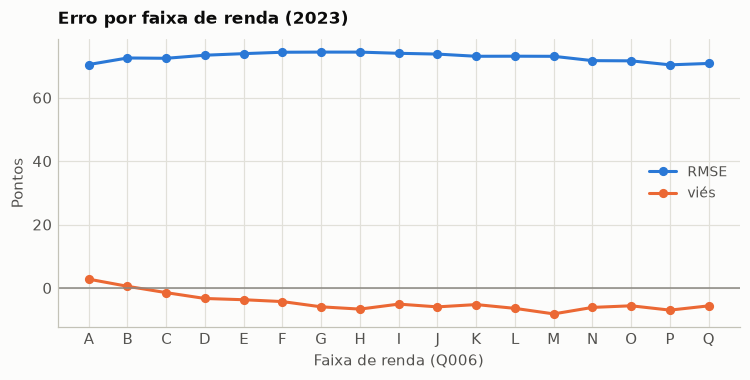

In [27]:
renda = por_grupo("Q006"); renda.to_csv(C.TAB_DIR / "erro_renda.csv")
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(range(len(renda)), renda["rmse"], marker="o", color=SERIES[0], label="RMSE")
ax.plot(range(len(renda)), renda["vies"], marker="o", color=SERIES[1], label="viés")
ax.axhline(0, color=MUTED, linewidth=1)
ax.set_xticks(range(len(renda)), renda.index); ax.set_xlabel("Faixa de renda (Q006)"); ax.set_ylabel("Pontos"); ax.legend()
ax.set_title("Erro por faixa de renda (2023)"); plots.save(fig, "erro_renda")